# ¿Cuánto de catalán tiene NLLB? Probabilidades token a token

Este notebook mira **dentro de la distribución del modelo**: en vez de ver solo la traducción
final, calcula con qué probabilidad el decoder quiere poner una palabra frente a otra
(p. ej. *xiquet* frente a *noi* o *nen*) justo en el punto donde se decide.

Cómo se usa NLLB en el resto del repo, que es lo que se reproduce aquí:

- Encoder: la frase en inglés tokenizada con `tokenizer.src_lang = "eng_Latn"`.
- Decoder: la secuencia es `[</s>, cat_Latn, t1, t2, ..., </s>]`. `</s>` es el
  `decoder_start_token_id`, y `cat_Latn` lo fuerza `generate(..., forced_bos_token_id=...)`,
  exactamente como en `src/trainer.py` (entrenamiento) y `metrics/decoding.py` (test).
- `get_log_probs` del trainer hace *teacher forcing*: `model(input_ids, attention_mask,
  decoder_input_ids=gen_ids[:, :-1])` y mira `logits[:, i]` para predecir el token `i+1`.
  Aquí hacemos lo mismo con prefijos que elegimos nosotros.

Esquema de la idea: la fila `i` de los logits es la distribución del **siguiente** token tras
`decoder_input_ids[:i+1]`. Si damos como prefijo `[</s>, cat_Latn, Aquest]`, la última fila es
la distribución sobre *noi / xiquet / nen / ...*.

**Qué hay**
0. Instalación (solo Colab).
1. Configuración y carga (base 600M/1.3B, adaptador opcional).
2. Cómo usa el modelo `generate` y comprobación de que el teacher forcing reproduce sus scores.
3. Funciones de probabilidad: siguiente token y palabra completa (varios tokens).
4. Casos conflictivos escritos a mano (frase en inglés + prefijo + candidatas).
5. Traza de una traducción: probabilidad y alternativas en cada posición.
6. Teacher forcing sobre **referencias valencianas reales** (UJI): dónde "se resiste" el modelo.

## 0. Instalación (solo Google Colab)

In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/DSPagan/reference-free-ft-rl-mt.git
    %cd reference-free-ft-rl-mt
    !pip install -q transformers sentencepiece accelerate bitsandbytes peft

Cloning into 'reference-free-ft-rl-mt'...
remote: Enumerating objects: 131, done.
remote: Counting objects: 100% (131/131), done.
remote: Compressing objects: 100% (118/118), done.
remote: Total 131 (delta 5), reused 88 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (131/131), 13.41 MiB | 16.93 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/reference-free-ft-rl-mt


## 1. Configuración

In [2]:
import contextlib
import os
import sys

# El notebook vive en notebooks/: añadimos la raíz del repo al path para importar src/
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)

SCALE = "1.3b"          # "600m" | "1.3b"
USE_4BIT = None         # None -> 4-bit NF4 (como en entrenamiento) si hay CUDA, fp32 si no
ADAPTER_PATH = None     # p. ej. "../results/cat_Latn_600m_en_ipd_uji/adapters_best/cat_Latn"
SRC_LANG, TGT_LANG = "eng_Latn", "cat_Latn"
TRAIN_TEMPERATURE = 1.2 # temperatura de muestreo del entrenamiento (main.py --temp_initial)
K = 12                  # muestras por grupo GRPO (main.py --k)

In [3]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

SCALE_TO_MODEL = {
    "600m": "facebook/nllb-200-distilled-600M",
    "1.3b": "facebook/nllb-200-distilled-1.3B",
}
MODEL_NAME = SCALE_TO_MODEL[SCALE]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
use_4bit = torch.cuda.is_available() if USE_4BIT is None else USE_4BIT

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, src_lang=SRC_LANG)
if use_4bit:
    from src.models import load_vanilla_model   # el mismo 4-bit NF4 del resto del repo
    base_model = load_vanilla_model(MODEL_NAME)
else:
    base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32).to(DEVICE).eval()

model = base_model
if ADAPTER_PATH:
    from peft import PeftModel
    model = PeftModel.from_pretrained(base_model, ADAPTER_PATH).eval()

TGT_ID = tokenizer.convert_tokens_to_ids(TGT_LANG)
START_ID = base_model.config.decoder_start_token_id
EOS_ID = tokenizer.eos_token_id
print(f"{MODEL_NAME} | {'4-bit' if use_4bit else 'fp32'} | device={DEVICE} | adapter={ADAPTER_PATH}")
print(f"decoder_start_token_id={START_ID} ({tokenizer.convert_ids_to_tokens(START_ID)}), "
      f"{TGT_LANG} id={TGT_ID}, eos id={EOS_ID}")


def systems():
    """(label, context manager) for each system to compare: trained (if any adapter) and base."""
    if ADAPTER_PATH:
        return [("trained", contextlib.nullcontext()), ("base", model.disable_adapter())]
    return [("base", contextlib.nullcontext())]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/808 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.48GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1016 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

facebook/nllb-200-distilled-1.3B | 4-bit | device=cuda | adapter=None
decoder_start_token_id=2 (</s>), cat_Latn id=256034, eos id=2


## 2. Cómo usa el modelo `generate` y qué devuelve

Generamos una frase como en el test (beam) o en el entrenamiento (muestreo a T=1.2) y miramos
la secuencia de ids y los `scores`. Después comprobamos que el *teacher forcing* con esos mismos
ids reproduce las probabilidades que vio `generate`.

In [4]:
def generate(src, mode="beam", **extra):
    """Misma llamada que metrics/decoding.py (beam) o src/trainer.py (sample)."""
    inputs = tokenizer(src, return_tensors="pt").to(DEVICE)
    kw = {"beam": dict(num_beams=5, max_new_tokens=128),
          "greedy": dict(do_sample=False, max_new_tokens=128),
          "sample": dict(do_sample=True, temperature=TRAIN_TEMPERATURE, max_new_tokens=64)}[mode]
    with torch.no_grad():
        return model.generate(**inputs, forced_bos_token_id=TGT_ID, return_dict_in_generate=True,
                               output_scores=True, **kw, **extra)


src = "This boy is very tired because he did not sleep last night."
out = generate(src, "greedy")
ids = out.sequences[0].tolist()
print("ids   :", ids)
print("tokens:", tokenizer.convert_ids_to_tokens(ids))
print("texto :", tokenizer.decode(ids, skip_special_tokens=True))
print(f"\nlen(scores) = {len(out.scores)}  (uno por token generado tras el de inicio; forma de cada uno: "
      f"{tuple(out.scores[0].shape)} = [beams, vocab])")

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ids   : [2, 256034, 46664, 14780, 23058, 18105, 75469, 20, 35550, 254, 287, 77559, 170978, 9, 82, 8231, 248075, 2]
tokens: ['</s>', 'cat_Latn', '▁Aquest', '▁noi', '▁està', '▁molt', '▁cans', 'at', '▁perquè', '▁no', '▁va', '▁dormir', '▁ahir', '▁a', '▁la', '▁nit', '.', '</s>']
texto : Aquest noi està molt cansat perquè no va dormir ahir a la nit.

len(scores) = 17  (uno por token generado tras el de inicio; forma de cada uno: (1, 256206) = [beams, vocab])


**Lectura.** `ids[0]` es `</s>` (inicio del decoder) e `ids[1]` es `cat_Latn`: `generate` lo
fuerza en el primer paso, y por eso `scores[0]` tiene todo a `-inf` salvo ese token. Lo que
decide el modelo empieza en `ids[2]`.

In [5]:
@torch.no_grad()
def decoder_logits(src, real_ids):
    """Teacher forcing: logits [2 + len(real_ids), vocab] con decoder_input_ids = [</s>, cat_Latn, *real_ids].

    La fila r es la distribución del token siguiente a decoder_input[:r+1]: la fila 0 predice
    cat_Latn, la fila 1 el primer token real y la fila 1 + n la del token tras n tokens reales.
    """
    enc = tokenizer(src, return_tensors="pt").to(DEVICE)
    dec = torch.tensor([[START_ID, TGT_ID] + list(real_ids)], device=DEVICE)
    return model(**enc, decoder_input_ids=dec).logits[0].float()


# Comprobación: con greedy, el teacher forcing sobre la secuencia generada reproduce a generate
real = ids[2:-1] if ids[-1] == EOS_ID else ids[2:]
tf_logp = F.log_softmax(decoder_logits(src, real), dim=-1)           # filas 0 .. n+1
gen_logp = [F.log_softmax(s[0].float(), dim=-1) for s in out.scores]  # un paso de generate cada una
n_check = len(gen_logp)
diffs = []
for t in range(1, n_check):            # t=0 es el paso forzado (cat_Latn)
    tok = ids[t + 1]
    diffs.append((tf_logp[t, tok] - gen_logp[t][tok]).abs().item())
    assert tf_logp[t].argmax().item() == gen_logp[t].argmax().item() == tok, f"argmax distinto en el paso {t}"
print(f"greedy: el argmax coincide en los {n_check - 1} pasos; max |diff logprob| = {max(diffs):.2e}")

greedy: el argmax coincide en los 16 pasos; max |diff logprob| = 2.74e-02


## 3. Funciones de probabilidad

- `next_token_table(src, prefix_text)`: top-k tokens siguientes tras un prefijo (una palabra
  puede ocupar **varios** tokens SentencePiece, p. ej. `▁xi` + `quet`).
- `candidate_table(src, prefix_text, candidates)`: probabilidad de cada **palabra completa**
  candidata dada la frase y el prefijo, multiplicando la de sus tokens. Se da a T=1 (lo que
  cree el modelo, y lo que ve el beam search) y a T=1.2 (la distribución de la que muestrea el
  entrenamiento: `softmax(logits / T)`), y la probabilidad de que **al menos una de las K
  muestras** escoja esa palabra en ese punto, `1 - (1 - p_T)^K`.

Todas las probabilidades son **condicionadas al prefijo** que damos.

In [6]:
def text_to_ids(text):
    """Ids de las piezas SentencePiece de un texto en catalán, sin tokens especiales."""
    return tokenizer.convert_tokens_to_ids(tokenizer.tokenize(text)) if text else []


def split_candidate(prefix_text, cand):
    """Tokens de `cand` como continuación de `prefix_text` (tokenizando el texto completo)."""
    prefix_ids = text_to_ids(prefix_text)
    full_ids = text_to_ids(f"{prefix_text} {cand}" if prefix_text else cand)
    if full_ids[:len(prefix_ids)] != prefix_ids:
        print(f"[aviso] '{cand}' cambia la tokenización del prefijo '{prefix_text}'; resultados aproximados")
    return prefix_ids, full_ids[len(prefix_ids):]


def show(ids_):
    return " ".join(tokenizer.convert_ids_to_tokens(ids_))


def next_token_table(src, prefix_text="", k=10, temperature=1.0):
    """Top-k del token siguiente tras el prefijo (teacher forcing)."""
    prefix_ids = text_to_ids(prefix_text)
    logits = decoder_logits(src, prefix_ids)[-1]
    probs = F.softmax(logits / temperature, dim=-1)
    top = probs.topk(k)
    return pd.DataFrame({"token": tokenizer.convert_ids_to_tokens(top.indices.tolist()),
                         "prob": top.values.tolist()})


def candidate_table(src, prefix_text, candidates, temperature=TRAIN_TEMPERATURE, k_samples=K):
    """Probabilidad de cada palabra candidata como continuación del prefijo."""
    rows = []
    for cand in candidates:
        prefix_ids, cand_ids = split_candidate(prefix_text, cand)
        logits = decoder_logits(src, prefix_ids + cand_ids)
        first_row = len(prefix_ids) + 1               # fila que predice el primer token de la candidata
        rows_idx = [first_row + i for i in range(len(cand_ids))]
        lp1 = F.log_softmax(logits, dim=-1)
        lpT = F.log_softmax(logits / temperature, dim=-1)
        p1 = float(torch.exp(sum(lp1[r, t] for r, t in zip(rows_idx, cand_ids))))
        pT = float(torch.exp(sum(lpT[r, t] for r, t in zip(rows_idx, cand_ids))))
        rows.append({"candidata": cand, "tokens": show(cand_ids),
                     "p_1er_token": float(torch.exp(lp1[rows_idx[0], cand_ids[0]])),
                     "p (T=1)": p1, f"p (T={temperature})": pT,
                     f"P(>=1 de {k_samples})": 1 - (1 - pT) ** k_samples})
    df = pd.DataFrame(rows)
    df["reparto entre candidatas (T=1)"] = df["p (T=1)"] / df["p (T=1)"].sum()
    return df

## 4. Casos conflictivos

Cada caso es una frase en inglés, un **prefijo** en catalán/valenciano (lo que el decoder ya
ha escrito) y las palabras candidatas entre las que se decide justo después. Son ejemplos:
edítalos o añade los tuyos. `prefix=""` significa «primera palabra de la frase».

Un buen caso es aquel en que el prefijo es válido en las dos variantes y la palabra siguiente
distingue entre ellas.

In [7]:
CASES = [
    dict(name="xiquet / noi / nen",
         src="This boy is very tired because he did not sleep last night.",
         prefix="Aquest", candidates=["xiquet", "noi", "nen", "xic"]),
    dict(name="demostrativo inicial",
         src="This is a very important decision for the university.",
         prefix="", candidates=["Aquesta", "Esta"]),
    dict(name="subjuntivo (vinga / vingui)",
         src="I want him to come to my house tomorrow.",
         prefix="Vull que", candidates=["vinga", "vingui"]),
    dict(name="tomaca / tomàquet",
         src="We bought a kilo of tomatoes at the market.",
         prefix="Vam comprar un quilo de", candidates=["tomaques", "tomàquets", "tomates"]),
    dict(name="préssec / bresquilla",
         src="She ate a peach after lunch.",
         prefix="Va menjar un", candidates=["préssec", "bresquilla"]),
]


def run_case(case, top_k=8):
    src, prefix = case["src"], case["prefix"]
    print("=" * 90)
    print(f"{case['name']}\nEN: {src}\nprefijo decoder: '{prefix}'")
    for label, ctx in systems():
        with ctx:
            print(f"\n--- {label} ---  beam-5: {tokenizer.decode(generate(src).sequences[0], skip_special_tokens=True)}")
            print(f"Top-{top_k} del siguiente token (T=1):")
            display(next_token_table(src, prefix, k=top_k).style.format({"prob": "{:.4f}"}))
            display(candidate_table(src, prefix, case["candidates"]).style.format(
                {c: "{:.4f}" for c in ["p_1er_token", "p (T=1)", f"p (T={TRAIN_TEMPERATURE})",
                                       f"P(>=1 de {K})", "reparto entre candidatas (T=1)"]}))


for c in CASES:
    run_case(c)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


xiquet / noi / nen
EN: This boy is very tired because he did not sleep last night.
prefijo decoder: 'Aquest'

--- base ---  beam-5: Aquest noi està molt cansat perquè no va dormir ahir a la nit.
Top-8 del siguiente token (T=1):


,token,prob
0,▁noi,0.5736
1,▁nen,0.1643
2,▁xi,0.0501
3,▁jove,0.0222
4,▁x,0.0163
5,▁nois,0.0093
6,▁no,0.0072
7,▁fill,0.0068


,candidata,tokens,p_1er_token,p (T=1),p (T=1.2),P(>=1 de 12),reparto entre candidatas (T=1)
0,xiquet,▁xi quet,0.0501,0.0467,0.0244,0.2564,0.0585
1,noi,▁noi,0.5736,0.5736,0.2905,0.9837,0.7194
2,nen,▁nen,0.1643,0.1643,0.1025,0.7269,0.2061
3,xic,▁x ic,0.0163,0.0127,0.0057,0.0660,0.0159


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,candidata,tokens,p_1er_token,p (T=1),p (T=1.2),P(>=1 de 12),reparto entre candidatas (T=1)
0,tomaques,▁toma ques,0.0134,0.0001,0.0000,0.0005,0.0002
1,tomàquets,▁tom à qu ets,0.7787,0.2727,0.0329,0.3305,0.9177
2,tomates,▁tom ates,0.7787,0.0244,0.0141,0.1564,0.0821


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


préssec / bresquilla
EN: She ate a peach after lunch.
prefijo decoder: 'Va menjar un'

--- base ---  beam-5: Va menjar un pêsseg després del dinar.
Top-8 del siguiente token (T=1):


,token,prob
0,▁pê,0.2069
1,▁pes,0.1422
2,▁pic,0.0761
3,▁ber,0.0631
4,▁melo,0.0593
5,▁pe,0.0383
6,▁peix,0.0280
7,▁per,0.0205


,candidata,tokens,p_1er_token,p (T=1),p (T=1.2),P(>=1 de 12),reparto entre candidatas (T=1)
0,préssec,▁prés sec,0.0001,0.0001,0.0001,0.0009,0.1513
1,bresquilla,▁bres quilla,0.0150,0.0005,0.0002,0.0025,0.8487


**Cómo leer las tablas**

- `p (T=1)`: lo que el modelo "quiere" escribir. Si `noi`/`nen` suman mucho más que `xiquet`,
  el modelo es catalán en esa decisión.
- `p (T=1.2)` y `P(>=1 de 12)`: lo que ve GRPO. Si `P(>=1 de 12)` es casi 0 para la forma
  valenciana, ningún grupo de 12 la contiene y la recompensa IPD no puede distinguirla
  (la hipótesis de las 12 frases «todas catalanas»). Nota: es solo en **ese punto**; una frase
  entera tiene muchos puntos de decisión y la forma valenciana puede aparecer en otro.
- `reparto entre candidatas`: normaliza solo entre las que listamos, para comparar formas
  sin que el resto del vocabulario pese.
- La probabilidad de una palabra es la de sus tokens; no incluye que ahí termine la palabra
  (`noi` frente a `noia`). Para eso, mirar `p_1er_token` y el top-k.

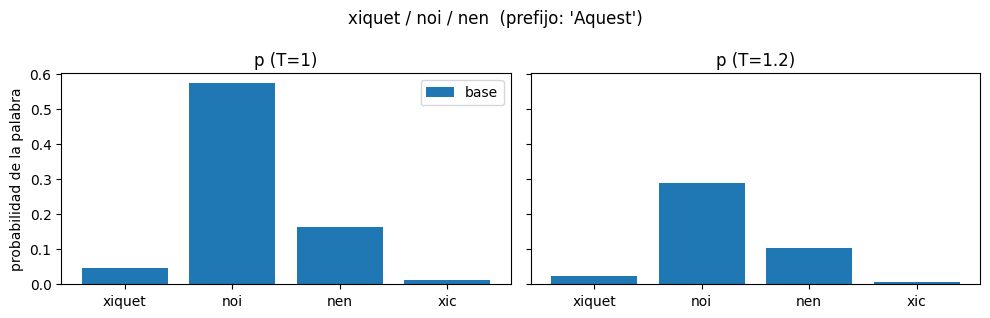

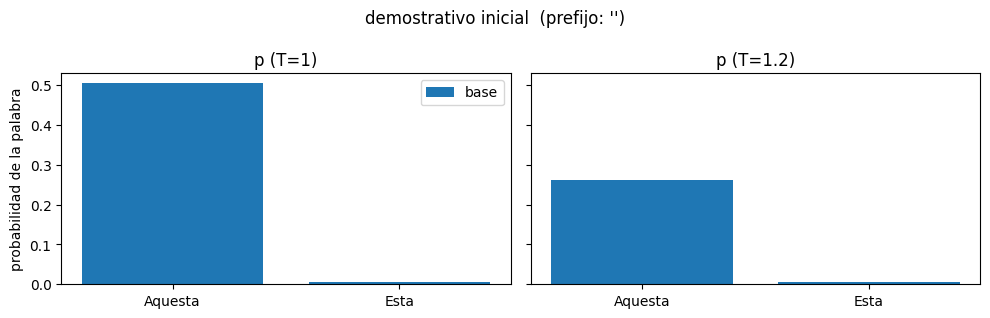

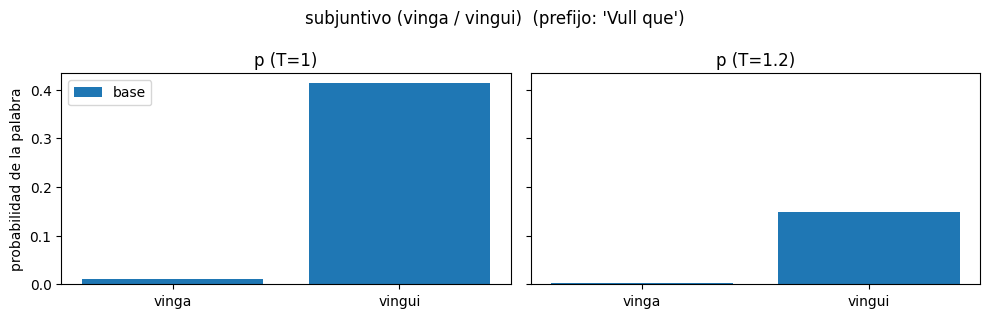

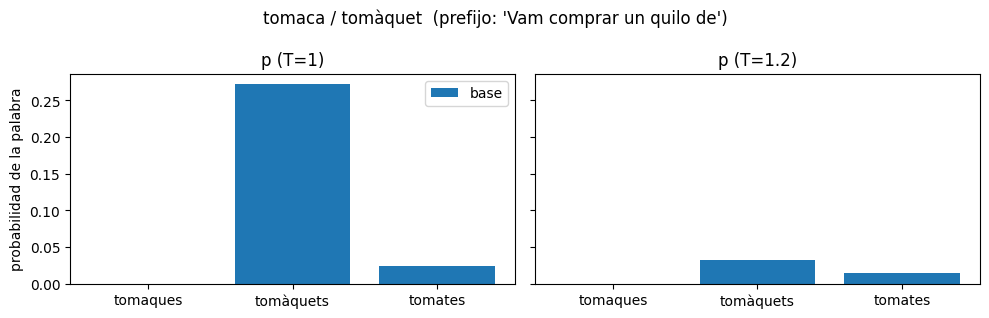

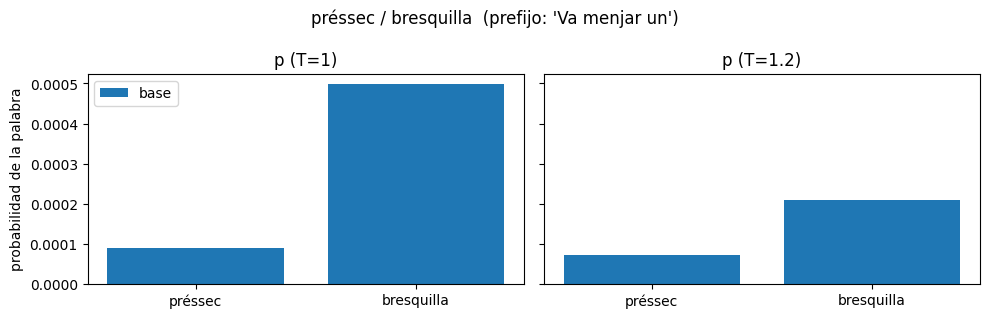

In [8]:
import matplotlib.pyplot as plt


def plot_case(case):
    """Barras de p(T=1) y p(T=train) por candidata y sistema."""
    sys_tabs = {}
    for label, ctx in systems():
        with ctx:
            sys_tabs[label] = candidate_table(case["src"], case["prefix"], case["candidates"])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
    for ax, col in zip(axes, ["p (T=1)", f"p (T={TRAIN_TEMPERATURE})"]):
        w = 0.8 / len(sys_tabs)
        for i, (label, df) in enumerate(sys_tabs.items()):
            ax.bar(np.arange(len(df)) + i * w, df[col], w, label=label)
        ax.set_xticks(np.arange(len(df)) + w * (len(sys_tabs) - 1) / 2)
        ax.set_xticklabels(df["candidata"])
        ax.set_title(col)
    axes[0].set_ylabel("probabilidad de la palabra")
    axes[0].legend()
    fig.suptitle(f"{case['name']}  (prefijo: '{case['prefix']}')")
    fig.tight_layout()
    plt.show()


for c in CASES:
    plot_case(c)

## 5. Traza de una traducción: qué dudaba el modelo en cada posición

Traduce una frase (beam como en el test, o `mode="sample"` como en el entrenamiento) y, con
teacher forcing sobre el resultado, lista en cada posición la probabilidad del token elegido
y las mejores alternativas. Las posiciones con `duda=True` (token elegido con p < 0.5) son los
puntos donde hay una decisión real, y entre las alternativas se ve si aparecen variantes
valencianas.

In [9]:
def trace_translation(src, mode="beam", n_alt=4, doubt_below=0.5):
    out = generate(src, mode)
    seq = out.sequences[0].tolist()
    targets = seq[2:]                                   # tokens reales + </s>
    real = targets[:-1] if targets and targets[-1] == EOS_ID else targets
    probs = F.softmax(decoder_logits(src, real)[1:], dim=-1)   # filas que predicen cada target
    rows = []
    for pos, tok in enumerate(targets):
        top = probs[pos].topk(n_alt + 1)
        alts = [(tokenizer.convert_ids_to_tokens(i), p) for i, p in zip(top.indices.tolist(), top.values.tolist())
                if i != tok][:n_alt]
        p = probs[pos, tok].item()
        rows.append({"pos": pos, "token": tokenizer.convert_ids_to_tokens(tok), "p": p, "duda": p < doubt_below,
                     "alternativas": ", ".join(f"{t} ({q:.2f})" for t, q in alts)})
    return tokenizer.decode(seq, skip_special_tokens=True), pd.DataFrame(rows)


for label, ctx in systems():
    with ctx:
        text, trace = trace_translation("This boy is very tired because he did not sleep last night.")
        print(f"--- {label} ---\n{text}")
        display(trace[trace["duda"]].style.format({"p": "{:.3f}"}))

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- base ---
Aquest noi està molt cansat perquè no va dormir ahir a la nit.


,pos,token,p,duda,alternativas


## 6. Teacher forcing sobre referencias valencianas reales (UJI)

Es la idea del esquema con datos reales: encoder = frase en inglés, decoder = la **traducción
valenciana de referencia** completa. En cada posición vemos cuánta probabilidad le da el modelo
al token valenciano y cuál habría preferido él. Donde `p(ref)` es baja y `top1` es otra cosa,
el modelo «se resiste»: candidatos a catalanismos sistemáticos, sin escribir listas a mano.
(El contexto es el prefijo *valenciano* de la referencia, no lo que el modelo habría escrito.)

In [10]:
DATA_SPLIT = os.path.join(ROOT, "data", "uji_eng", TGT_LANG, "dev.parquet")
N_SENTENCES = 100
df_ref = pd.read_parquet(DATA_SPLIT).sample(n=N_SENTENCES, random_state=0).reset_index(drop=True)


def score_reference(src, ref):
    """Por token de la referencia: p(ref), top-1 del modelo y su probabilidad (teacher forcing)."""
    ref_ids = text_to_ids(ref)
    logp = F.log_softmax(decoder_logits(src, ref_ids)[1:len(ref_ids) + 1], dim=-1)  # filas que predicen ref_ids
    top1 = logp.argmax(dim=-1)
    ref_t = torch.tensor(ref_ids, device=logp.device)
    return pd.DataFrame({
        "token": tokenizer.convert_ids_to_tokens(ref_ids),
        "p_ref": logp.gather(1, ref_t[:, None])[:, 0].exp().tolist(),
        "top1": tokenizer.convert_ids_to_tokens(top1.tolist()),
        "p_top1": logp.max(dim=-1).values.exp().tolist(),
    })


all_scores = {}
for label, ctx in systems():
    with ctx:
        all_scores[label] = [score_reference(r.src, r.ref) for r in df_ref.itertuples()]

summary = pd.DataFrame({
    label: {"log-prob media por token de la ref. valenciana": float(np.mean(np.concatenate(
                [np.log(s.p_ref.clip(lower=1e-12)) for s in scs]))),
            "% tokens donde el top-1 del modelo != ref": 100 * float(np.mean(np.concatenate(
                [(s.token != s.top1).to_numpy() for s in scs])))}
    for label, scs in all_scores.items()})
display(summary)

,base
log-prob media por token de la ref. valenciana,-0.891720
% tokens donde el top-1 del modelo != ref,18.122363


In [11]:
def resisted_pairs(scs, p_ref_below=0.2, top=25):
    """Pares (token valenciano de la ref -> token que prefiere el modelo) más frecuentes."""
    rows = pd.concat(scs)
    rows = rows[(rows.token != rows.top1) & (rows.p_ref < p_ref_below)]
    pairs = rows.groupby(["token", "top1"]).agg(veces=("p_ref", "size"), p_ref_media=("p_ref", "mean"),
                                               p_top1_media=("p_top1", "mean")).reset_index()
    return pairs.sort_values("veces", ascending=False).head(top)


for label, scs in all_scores.items():
    print(f"--- {label}: referencia -> lo que el modelo prefiere (p(ref) < 0.2) ---")
    display(resisted_pairs(scs).style.format({"p_ref_media": "{:.3f}", "p_top1_media": "{:.3f}"}))

--- base: referencia -> lo que el modelo prefiere (p(ref) < 0.2) ---


,token,top1,veces,p_ref_media,p_top1_media
12,,',19,0.011,0.869
125,▁,"▁""",10,0.000,0.754
17,,,10,0.013,0.645
529,▁seua,▁seva,9,0.046,0.752
257,▁d,▁de,8,0.088,0.700
412,▁la,▁l,6,0.070,0.622
282,▁del,▁de,5,0.073,0.678
527,▁seu,▁seves,5,0.059,0.808
264,▁de,",",4,0.034,0.611
174,▁a,▁als,4,0.083,0.768


In [12]:
# Una frase concreta, con las posiciones más "sorprendentes" para el modelo
i = 0
row = df_ref.iloc[i]
print("EN :", row.src)
print("VA :", row.ref)
for label, ctx in systems():
    s = all_scores[label][i]
    print(f"\n--- {label}: tokens de la ref. con menor probabilidad ---")
    display(s.sort_values("p_ref").head(8).style.format({"p_ref": "{:.4f}", "p_top1": "{:.4f}"}))

EN : Futher information: https://www.uji.es/serveis/use/base/orientacio/majorsde/.
VA : Pàgina web sobre les proves: https://www.uji.es/serveis/use/base/orientacio/majorsde/.

--- base: tokens de la ref. con menor probabilidad ---


,token,p_ref,top1,p_top1
0,▁Pà,0.0001,▁Més,0.3982
3,▁sobre,0.0039,▁de,0.2400
5,▁proves,0.0047,▁empreses,0.0442
6,:,0.0615,▁de,0.2017
4,▁les,0.0749,▁el,0.1314
7,▁https,0.3135,▁https,0.3135
2,▁web,0.3221,▁web,0.3221
30,.,0.4850,.,0.4850


## Siguientes pasos posibles

- Sustituir `CASES` por frases con las formas que AVLizador marca como valencianas y
  orientales, para medir con el IPD «real» qué decisiones concretas pesan.
- Poner `ADAPTER_PATH` y comparar `trained` frente a `base`: si el entrenamiento ha subido
  `p (T=1)` de la forma valenciana en los casos de la sección 4 y la log-prob de la sección 6.
- Cambiar `SCALE = "1.3b"` para ver si el modelo grande es menos catalán en las mismas decisiones.